In [1]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
from qudit_nh_design import *

Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 0.]] Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 1.]]


In [2]:
Q = np.zeros([3,3])
Q[2,2]=1
Q=qt.Qobj(Q)
P=1-Q
print(P,Q)

Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 0.]] Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 1.]]


## 1 - Three examples of non-Hermitian dynamics
### 1.1 - Single steady-state, high entropy

In [16]:
N=4
h, J, Omega= 1,8.0, 0.5
tf = 20
nstep = 200
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf

#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

#--- target effective Hamiltonian
heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)

print(H_qutrit.isherm,H_qeff.isherm)
psi0 = qt.basis([3]*N,n=[1,0]*(N//2))
psi0_eff = qt.basis([2]*N,n=[1,0]*(N//2))
psi0 = qt.tensor([(qt.basis(3,n=1)+qt.basis(3,n=0)).unit()]*N)
psi0_eff = qt.tensor([(qt.basis(2,n=1)+qt.basis(2,n=0)).unit()]*N)

Z01 = embedded_pauli('z',0,1)
print(Z01)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
print(qt.expect(e_evo,psi0))
options={'progress':False}

effective paramters: lambda_1=0.00-0.01j, lambda_2=0.00-1.60j
True False
Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  0.]]
[1.3877787807814457e-17, 1.3877787807814457e-17, 0.0, 0.0]


In [17]:
res = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options=options)
'''
res_rand = time_evo(H_qutrit,psi0,trand,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options={'uniform_dt':False, 'progress':False})
'''

res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff, options=options)

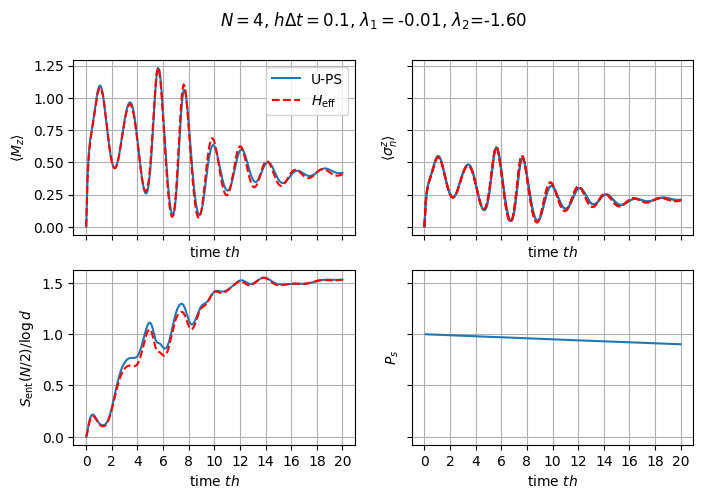

In [18]:

fig,ax = plt.subplots(nrows=2,ncols=2,sharex=True, sharey='row')
fig.set_size_inches([8,5])
fig.suptitle(rf"$N={N}$, $h\Delta t=0.1$, $\lambda_1=${lambda1.imag:.2f}, $\lambda_2$={lambda2.imag:.2f}")
ax[0,0].plot(tvec,sum(res.expect)/2,label='U-PS')
#ax[0].plot(trand,sum(res_rand.expect)/2,'g-.',label='R-PS')
ax[0,0].plot(tvec,sum(res2.expect)/2,'r--',label=r'$H_{\rm eff}$')
ax[1,0].set_xlabel(r'time $t h$')
ax[1,1].set_xlabel(r'time $t h$')
ax[0,0].set_xlabel(r'time $t h$')
ax[0,0].set_ylabel(r'$\langle M_z \rangle$')
ax[0,0].legend()
ax[0,0].grid()
ax[0,0].set_xticks(np.arange(0,22,2))

ax[0,1].grid()
ax[0,1].plot(tvec,np.array(res.expect[0::2]).mean(axis=0),label='U-PS',c='C0')
ax[0,1].plot(tvec,np.array(res.expect[1::2]).mean(axis=0),label='U-PS',c='C0')
#ax[1].plot(trand,res_rand.expect[0],'g-.',label='R-PS')
#ax[1].plot(trand,res_rand.expect[1],'g-.',label='R-PS')
ax[0,1].plot(tvec,np.array(res2.expect[0::2]).mean(axis=0),'r--',label=r'$H_{\rm eff}$')
ax[0,1].plot(tvec,np.array(res2.expect[1::2]).mean(axis=0),'r--',label=r'$H_{\rm eff}$')
ax[0,1].set_xlabel(r'time $t h$')
ax[0,1].set_ylabel(r'$\langle \sigma^z_n \rangle$')



ax[1,0].plot(tvec,get_entanglement(res.states,[j for j in range(N//2)])/np.log(2))
ax[1,0].plot(tvec,get_entanglement(res2.states,[j for j in range(N//2)])/np.log(2),'r--')
ax[1,0].grid()
ax[1,0].set_ylabel(r'$S_{\rm ent}(N/2)/\log d$')

ax[1,1].plot(tvec[1:],np.cumprod(np.array(res.measurement_outcomes[1:]))) 
ax[1,1].set_ylabel(r'$P_s$')
ax[1,1].grid()
'''
plt.plot(tvec,res.expect[0])
plt.plot(tvec,res.expect[1])

plt.plot(trand,res_rand.expect[0],'-.')
plt.plot(trand,res_rand.expect[1],'-.')

plt.plot(tvec,res2.expect[0],'--')
plt.plot(tvec,res2.expect[1],'--')
plt.xlabel(r"time $t h_x$")
'''
fig.savefig(f'N{N}_entangled.pdf',bbox_inches='tight')

### 1.2 Doubly degenerate steady state.

In [38]:
N=4
h, J, Omega= 1,7.2, 5.3
tf = 15
nstep = 150
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf
trand = poisson_times(tf,rate)

#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

#--- target effective Hamiltonian
heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)

# sanity check that the full Hamiltonian is hermitian while the effective one is not
print(f"Hermiticity of full qutrit Hamiltonian:{H_qutrit.isherm}, effective Hamiltonian:{H_qeff.isherm})

psi0 = qt.basis([3]*N,n=[0,1]*(N//2))
psi0_eff = qt.basis([2]*N,n=[0,1]*(N//2))

#local observable      
Z01 = embedded_pauli('z',0,1)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
      
options={'progress':False}

res_qutrit = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options=options)

res_effective = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff, options=options)

effective paramters: lambda_1=0.00-0.70j, lambda_2=0.00-1.30j
True False
Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  0.]]
[ 1. -1.  1. -1.  1. -1.]


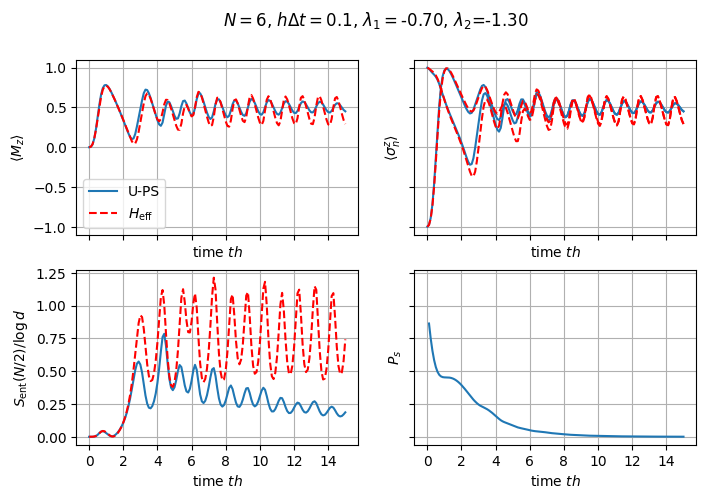

In [41]:

fig,ax = plt.subplots(nrows=2,ncols=2,sharex=True, sharey='row')
fig.set_size_inches([8,5])
fig.suptitle(rf"$N={N}$, $h\Delta t={tf/nstep:.1f}$, $\lambda_1=${lambda1.imag:.2f}, $\lambda_2$={lambda2.imag:.2f}")
ax[0,0].plot(tvec,sum(res.expect)/N,label='U-PS')
#ax[0].plot(trand,sum(res_rand.expect)/2,'g-.',label='R-PS')
ax[0,0].plot(tvec,sum(res2.expect)/N,'r--',label=r'$H_{\rm eff}$')
ax[1,0].set_xlabel(r'time $t h$')
ax[1,1].set_xlabel(r'time $t h$')
ax[0,0].set_xlabel(r'time $t h$')
ax[0,0].set_ylabel(r'$\langle M_z \rangle$')
ax[0,0].legend()
ax[0,0].grid()
ax[0,0].set_xticks(np.arange(0,16,2))

ax[0,1].grid()
ax[0,1].plot(tvec,np.array(res.expect[0::2]).mean(axis=0),label='U-PS',c='C0')
ax[0,1].plot(tvec,np.array(res.expect[1::2]).mean(axis=0),label='U-PS',c='C0')
#ax[1].plot(trand,res_rand.expect[0],'g-.',label='R-PS')
#ax[1].plot(trand,res_rand.expect[1],'g-.',label='R-PS')
ax[0,1].plot(tvec,np.array(res2.expect[0::2]).mean(axis=0),'r--',label=r'$H_{\rm eff}$')
ax[0,1].plot(tvec,np.array(res2.expect[1::2]).mean(axis=0),'r--',label=r'$H_{\rm eff}$')
ax[0,1].set_xlabel(r'time $t h$')
ax[0,1].set_ylabel(r'$\langle \sigma^z_n \rangle$')



ax[1,0].plot(tvec,get_entanglement(res.states,[j for j in range(N//2)])/np.log(3))
ax[1,0].plot(tvec,get_entanglement(res2.states,[j for j in range(N//2)])/np.log(2),'r--')
ax[1,0].grid()
ax[1,0].set_ylabel(r'$S_{\rm ent}(N/2)/\log d$')

ax[1,1].plot(tvec[1:],np.cumprod(np.array(res.measurement_outcomes[1:]))) 
ax[1,1].set_ylabel(r'$P_s$')
ax[1,1].grid()
fig.savefig('N{N}_oscillatory.pdf',bbox_inches='tight')

### 1.3 Single steady state, low entropy

In [42]:
N=6
h, J, Omega= 1,3.5, 5.1*np.sqrt(2)
tf = 15
nstep = 150
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf
trand = poisson_times(tf,rate)

#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

#--- target effective Hamiltonian
heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)

print(H_qutrit.isherm,H_qeff.isherm)
psi0 = qt.basis([3]*N,n=[0,1]*(N//2))
psi0_eff = qt.basis([2]*N,n=[0,1]*(N//2))

Z01 = embedded_pauli('z',0,1)
print(Z01)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
print(qt.expect(e_evo,psi0))
options={'progress':False}

res = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options=options)

#res_rand = time_evo(H_qutrit,psi0,trand,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
#               force_proj=True,options={'uniform_dt':False, 'progress':False})

res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff, options=options)

effective paramters: lambda_1=0.00-1.30j, lambda_2=0.00-0.31j
True False
Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  0.]]
[ 1. -1.  1. -1.  1. -1.]


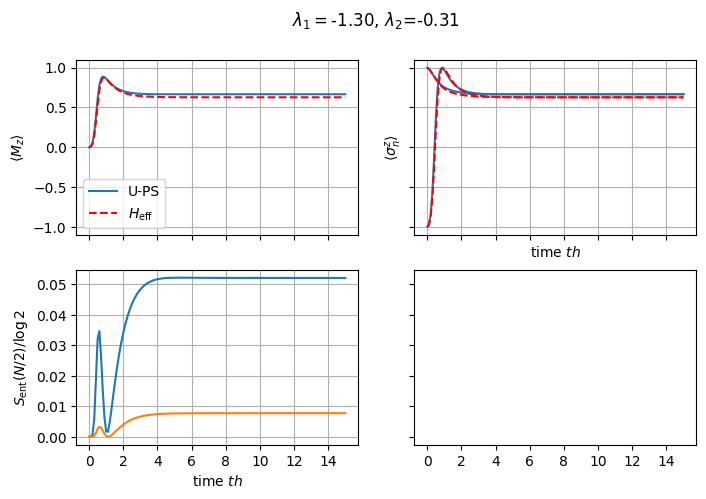

In [135]:

fig,ax = plt.subplots(nrows=2,ncols=2,sharex=True, sharey='row')
fig.set_size_inches([8,5])
fig.suptitle(rf"$N={N}$, $h\Delta t={tf/nstep:.1f}$, $\lambda_1=${lambda1.imag:.2f}, $\lambda_2$={lambda2.imag:.2f}")
ax[0,0].plot(tvec,sum(res.expect)/2,label='U-PS')
#ax[0].plot(trand,sum(res_rand.expect)/2,'g-.',label='R-PS')
ax[0,0].plot(tvec,sum(res2.expect)/2,'r--',label=r'$H_{\rm eff}$')
ax[1,0].set_xlabel(r'time $t h$')
ax[1,1].set_xlabel(r'time $t h$')
ax[0,0].set_xlabel(r'time $t h$')
ax[0,0].set_ylabel(r'$\langle M_z \rangle$')
ax[0,0].legend()
ax[0,0].grid()
ax[0,0].set_xticks(np.arange(0,16,2))

ax[0,1].grid()
ax[0,1].plot(tvec,np.array(res.expect[0::2]).mean(axis=0),label='U-PS',c='C0')
ax[0,1].plot(tvec,np.array(res.expect[1::2]).mean(axis=0),label='U-PS',c='C0')
#ax[1].plot(trand,res_rand.expect[0],'g-.',label='R-PS')
#ax[1].plot(trand,res_rand.expect[1],'g-.',label='R-PS')
ax[0,1].plot(tvec,np.array(res2.expect[0::2]).mean(axis=0),'r--',label=r'$H_{\rm eff}$')
ax[0,1].plot(tvec,np.array(res2.expect[1::2]).mean(axis=0),'r--',label=r'$H_{\rm eff}$')
ax[0,1].set_xlabel(r'time $t h$')
ax[0,1].set_ylabel(r'$\langle \sigma^z_n \rangle$')



ax[1,0].plot(tvec,get_entanglement(res.states,[j for j in range(N//2)])/np.log(3))
ax[1,0].plot(tvec,get_entanglement(res2.states,[j for j in range(N//2)])/np.log(2),'r--')
ax[1,0].grid()
ax[1,0].set_ylabel(r'$S_{\rm ent}(N/2)/\log d$')

ax[1,1].plot(tvec[1:],np.cumprod(np.array(res.measurement_outcomes[1:]))) 
ax[1,1].set_ylabel(r'$P_s$')
ax[1,1].grid()

fig.savefig('N{N}_separable.pdf',bbox_inches='tight')

## 2 - Phase diagram

In [11]:
N = 6
h=1
ns=100
lambda1_list=np.linspace(0.01,1.5,ns)
lambda2_list=np.linspace(0.01,1.5,ns)
gs_multiplicity = []
gs_entropy = []
gs_gap =[]
for lam1 in lambda1_list:
    for lam2 in lambda2_list:
        heff, lambda1, lambda2 = h, -1j*lam1, -1j*lam2
        #print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
        single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
        two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
        H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)
        res = nh_stationary_states(H_qeff,N, tol=1e-8,d=2)
        gs_multiplicity.append(res.degeneracy)
        gs_entropy.append(np.array(res.entanglement_entropies).mean())      
        gs_gap.append(-(res.steady_eigenvalue[-1]-res.steady_eigenvalue[0]).imag)

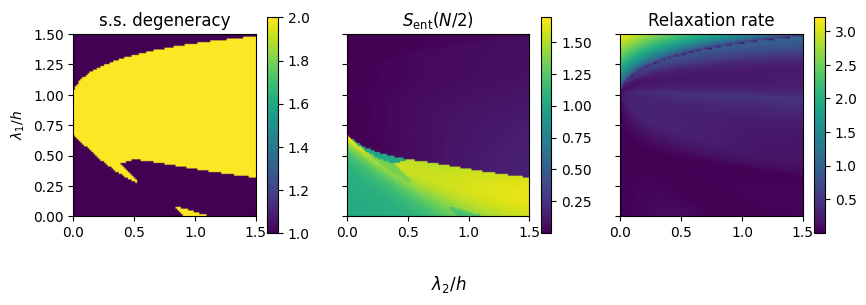

In [12]:
fig, ax = plt.subplots(ncols=3,sharex=True, sharey=True)
fig.set_size_inches([10,3.5])
fig.supxlabel(r'$\lambda_2/h$')
ax[0].set_ylabel(r'$\lambda_1/h$')
im=ax[0].imshow(np.array(gs_multiplicity).reshape([ns,ns]),origin='lower', extent=[0,1.5,0,1.5])
fig.colorbar(im,ax=ax[0],shrink=0.8)
ax[0].set_title('s.s. degeneracy')
im=ax[1].imshow(np.array(gs_entropy).reshape([ns,ns])/np.log(2),origin='lower', extent=[0,1.5,0,1.5])
fig.colorbar(im,ax=ax[1],shrink=0.8)
ax[1].set_title(r'$S_{\rm ent}(N/2)$')

im=ax[2].imshow((np.array(gs_gap)).reshape([ns,ns])/np.log(2),origin='lower', extent=[0,1.5,0,1.5])
fig.colorbar(im,ax=ax[2],shrink=0.8)
ax[2].set_title(r'Relaxation rate')

fig.savefig(f'phase_diagram_N{N}.pdf',bbox_inches='tight')

## Full stocastic dynamics

In [39]:
N=4
h, J, Omega= 1,4, 0.5
tf = 15
nstep = 150
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf
trand = poisson_times(tf,rate)

#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
psi0 = qt.basis([3]*N,n=[0,1]*(N//2))

Z01 = embedded_pauli('z',0,1)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]

res=run_trajectories(H_qutrit, psi0, tvec, P,N, measured_sites=[j for j in range(N)], 
                     ntraj = 100, e_ops = e_evo,n_jobs=10)

effective paramters: lambda_1=0.00-0.01j, lambda_2=0.00-0.40j


In [41]:
res=run_trajectories(H_qutrit, psi0, tvec, P,N, measured_sites=[j for j in range(N)], 
                     ntraj = 100, e_ops = e_evo,n_jobs=10)

Running 100 trajectories on 10 workers...


Trajectories: 100%|█████████████████████████████████████████████████████████████| 100/100 [00:29<00:00,  3.42traj/s]


In [10]:
def success_until_t(ps):
    for ntr, traj in enumerate(ps):
        for ist, pst in enumerate(traj):
            if not pst:
                traj[ist+1:]=False
                continue
        ps[ntr] = traj
    return ps

[]

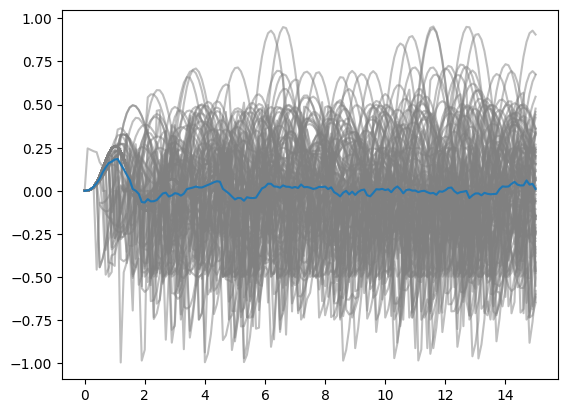

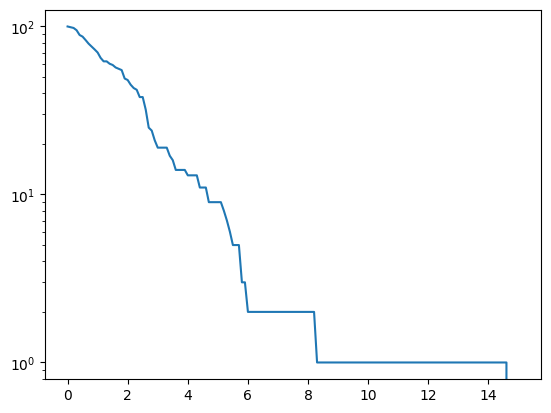

In [42]:
plt.plot(tvec,np.array(res.expect_traj).mean(axis=0).T,c='gray',alpha=0.5);
plt.plot(tvec,np.array(res.expect_mean).mean(axis=0))
plt.figure()
plt.plot(tvec,np.array(success_until_t(res.proj_traj)).sum(axis=0))
plt.semilogy()

## Comparison between diffeernt points in the phase diagram

effective paramters: lambda_1=0.00-0.00j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.01j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.03j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.05j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.08j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.11j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.15j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.20j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.25j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.31j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.38j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.45j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.53j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.61j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.70j, lambda_2=0.00-0.05j
effective paramters: lambda_1=0.00-0.80j, lambda_2=0.00-0.05j
effectiv

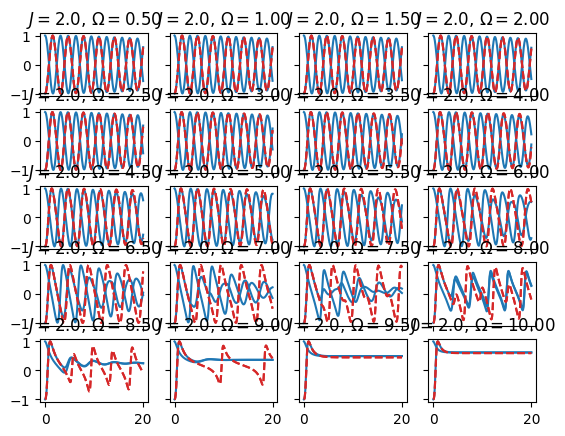

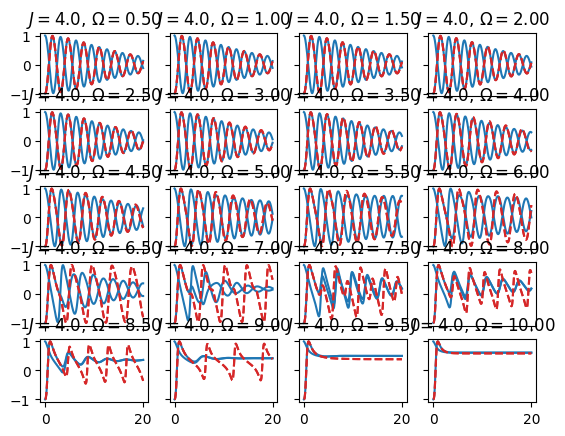

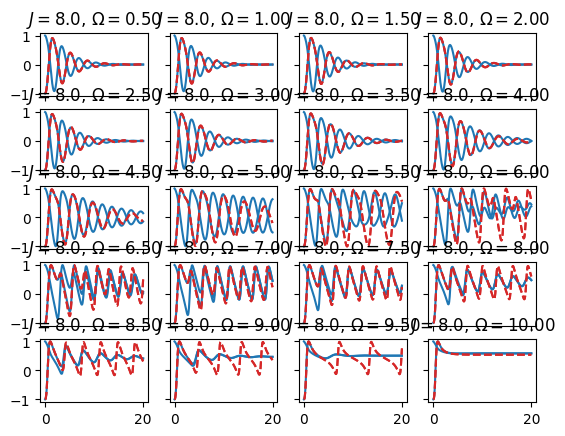

In [23]:
omega_list = np.linspace(0.5,10,20)
J_list = np.array([2.0,4.0,8.0])
Z01 = embedded_pauli('z',0,1)
tf = 20
nstep = 400
rate=nstep/tf
tvec = np.linspace(0,tf,nstep+1)
N=2
h=1

e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
data_dict=dict()

for J in J_list:
    fig, ax = plt.subplots(ncols=4,nrows=5,sharex=True, sharey=True)
    for iom, Omega in enumerate(omega_list):

        #--- full Hamiltonian with measurements
        single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
        two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
        H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)
        
        #--- target effective Hamiltonian
        heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
        print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
        single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
        two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
        H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)
    
        psi0 = qt.basis([3]*N,n=[0,1]*(N//2))
        psi0_eff = qt.basis([2]*N,n=[0,1]*(N//2))
    
        options={'progress':False}
        
        res = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
                       force_proj=True,options=options)
    
        res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff, options=options)
        data_dict['qutrit', J, Omega] = res.expect
        data_dict['eff', J, Omega] = res2.expect
        ax[iom//4,np.mod(iom,4)].set_title(rf"$J={J:.1f}$, $\Omega={Omega:.2f}$")
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(res.expect[0::2]).mean(axis=0),label='U-PS',c='C0')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(res.expect[1::2]).mean(axis=0),label='U-PS',c='C0')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(res2.expect[1::2]).mean(axis=0),'--',label='U-PS',c='C3')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(res2.expect[1::2]).mean(axis=0),'--',label='U-PS',c='C3')
        data_dict['err',J, Omega] = np.abs(np.array(res.expect)-np.array(res2.expect)).sum(axis=0)

In [ ]:
omega_list = np.linspace(0.5,10,20)
J_list = np.array([2.0,4.0,8.0])
Z01 = embedded_pauli('z',0,1)
tf = 20
nstep = 400
rate=nstep/tf
tvec = np.linspace(0,tf,nstep+1)
N=2
h=1


for J in J_list:
    fig, ax = plt.subplots(ncols=4,nrows=5,sharex=True, sharey=True)
    fig.set_size_inches([12,15])
    for iom, Omega in enumerate(omega_list):
        lambda1, lambda2 = Omega**2/rate/4, J**2/rate/4
        ax[iom//4,np.mod(iom,4)].set_title(rf"$\lambda_1={lambda1:.2f}$, $\lambda_2={lambda2:.2f}$")
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(data_dict['qutrit', J, Omega][0::2]).mean(axis=0),label='U-PS',c='C0')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(data_dict['qutrit', J, Omega][1::2]).mean(axis=0),label='U-PS',c='C0')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(data_dict['eff', J, Omega][0::2]).mean(axis=0),'--',label='U-PS',c='C3')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(data_dict['eff', J, Omega][1::2]).mean(axis=0),'--',label='U-PS',c='C3')
        fig.supxlabel(r'$\omega t$')
        fig.supylabel(r'$\langle \sigma^z_{e/o} \rangle$')

        fig.savefig(f'comparison_N{N}_rate{rate:.2f}.pdf',bbox_inches='tight')

                      


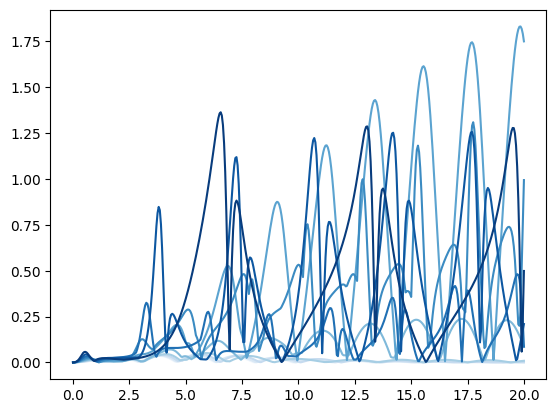

In [21]:
col = plt.cm.Blues(omega_list/max(omega_list))
J=8.0
for iom, omega in enumerate(omega_list[::2]):
    plt.plot(tvec, data_dict['err',J, omega],c=col[2*iom])